## Handwritten digit classifier
- Train a neural network that takes 28x28 image inputs and predict 0~9 what number it is.
- Implement the neural network and backpropagation algorithm from scratch with only numpy and no other ML library.

### 1. Load and inspect the image

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [28]:
seed = 42
rng = np.random.default_rng(seed)

data  = pd.read_csv('data/train.csv')
assert data.shape[1] == 785 and 'label' in data, "Expected label and 784 features in the dataset"
assert not data.isna().any().any(), "Dataset contains NaN values"
pixels = data.drop(columns='label').to_numpy(dtype = np.float64)
labels = data['label'].to_numpy(dtype = np.int64)
assert np.all((labels >= 0) & (labels <= 9)), "Labels must be in the range [0, 9]"
assert np.all((pixels >= 0) & (pixels <= 255)), "Pixel values must be in the range [0, 255]"
X = pixels / 255.0  # Normalize pixel values to [0, 1]
print(f"Loaded {len(X):,} \nExamples: X {X.shape}\nLabel {labels.shape}")

Loaded 42,000 
Examples: X (42000, 784)
Label (42000,)


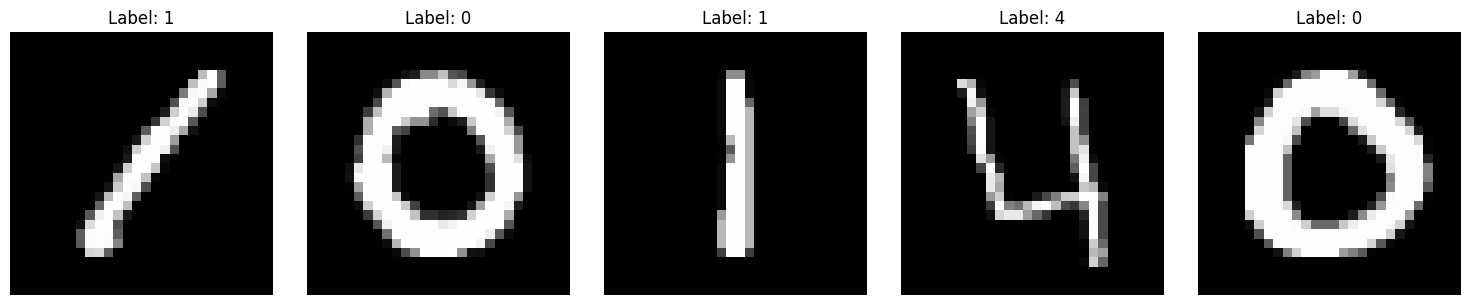

In [29]:
#show the first 5 examples
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, index in zip(axes, range(5)):
    ax.imshow(pixels[index].reshape(28, 28), cmap='gray', vmin = 0, vmax = 255)
    ax.set_title(f"Label: {labels[index]}")
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2. Auto-grad engine
- Followed the Andrej Karpathy's youtube video, but adjust to perform matrix operations

In [30]:
class Value:
    def __init__(self, data, _children=(), _op=''):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self.prev = tuple(_children)
        self._op = _op
        self._backward = lambda: None

    def __repr__(self):
        return f'Value(shape = {self.data.shape}, data = {self.data})'

    @staticmethod
    def unbroadcast(grad, shape):
        #sum the gradient back to original input's shape 
        while grad.dim > len(shape):
            #handle sum over extra dimensions
            grad  = grad.sum(axis = 0)
        for axis, size in enumerate(shape):
            #handle sum if original dimension have size 1
            if size == 1:
                grad = grad.sum(axis = axis, keepdims = True)
        return grad

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += self.unbroadcast(out.grad, self.data.shape)
            other.grad += self.unbroadcast(out.grad, other.data.shape)

        out._backward = _backward
        return out

    __radd__ = __add__

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += self.unbroadcast(other.data * out.grad, self.data.shape)
            other.grad += self.unbroadcast(self.data * out.grad, other.data.shape)

        out._backward = _backward
        return out

    __rmul__ = __mul__

    def __matmul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("Matrix multiplication required 2D arrays")

        out = Value(self.data @ other.data, (self, other), "@") #(a x b)x(b x c) = (a x c)
        def _backward():
            self.grad += out.grad @ other.data.T #(a x b) = (a x c)x(c x b)
            other.grad += self.data.T @ out.grad #(b x c) = (b x a)x(a x c)

        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += out.grad * (1 - t**2)

        out._backward = _backward

        return out

    def __pow__(self, power):
        if not isinstance(power, (int, float)):
            raise TypeError('Power nust be a numeric constant')

        out = Value(self.data ** power, (self, ), "**")
        def _backward():
            self.grad += out.grad * power * (self.data**(power-1))
        out._backward = _backward
        return out
